In [4]:
!mamba install pandas matplotlib seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 2.641 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.0.6    np23py313h124dbc7_0  emscripten-forge-4x
+ patsy          1.0.3    py313h1804a44_0      emscripten-forge-4x
+ python-tzdata  2026.5   pyh5ded981_0         conda-forge
+ seaborn        0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base   0.13.2   pyhd8ed1ab_3         conda-forge
+ statsmodels    0.14.6   np23py313hd8db738_2  emscripten-forge-4x
- pip            26.2.1   pyh145f28c_0         conda-forge


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
sns.set_theme(style="whitegrid")

In [7]:
plt.rcParams['figure.figsize'] = (8, 5)

In [8]:
plt.figure()

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

In [11]:
import pandas as pd

# Lê o ficheiro CSV e guarda na variável 'df'
df = pd.read_csv('train.csv')

print("Dados carregados com sucesso! Linhas e colunas:", df.shape)

Dados carregados com sucesso! Linhas e colunas: (891, 12)


/tmp/xpython_42/2813447449.py:1: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  ax = sns.barplot(data=df, x='Sex', y='Survived', ci=None, palette='Set2')
/tmp/xpython_42/2813447449.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df, x='Sex', y='Survived', ci=None, palette='Set2')


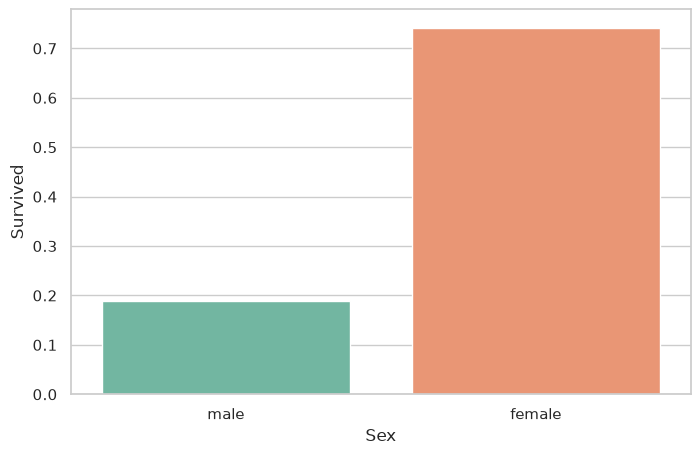

In [12]:
ax = sns.barplot(data=df, x='Sex', y='Survived', ci=None, palette='Set2')

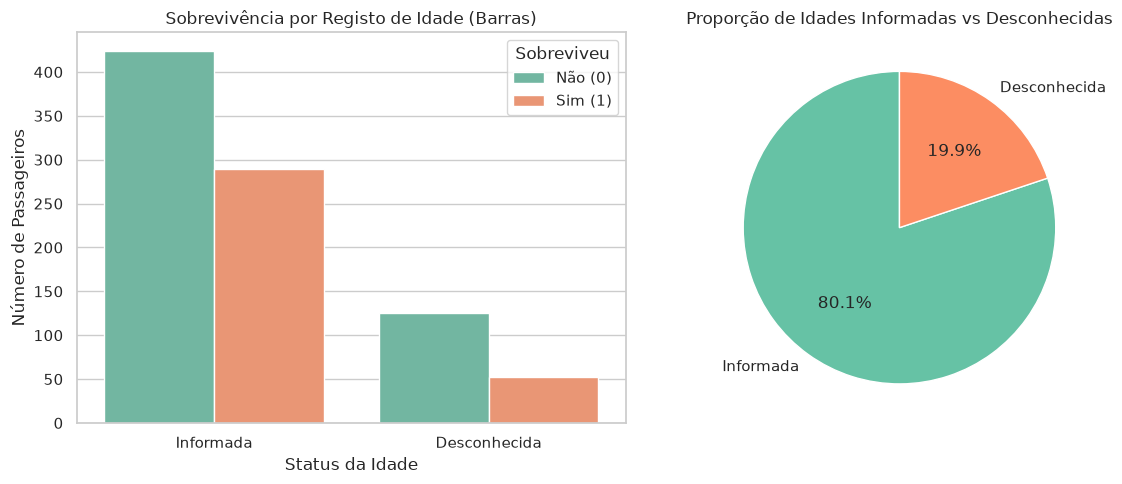

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Análise de Passageiros com Idade Desconhecida vs Informada
df['Age_Status'] = df['Age'].isnull().map({True: 'Desconhecida', False: 'Informada'})

plt.figure(figsize=(12, 5))

# Gráfico de Barras (Contagem de sobreviventes por status de idade)
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Age_Status', hue='Survived', palette='Set2')
plt.title('Sobrevivência por Registo de Idade (Barras)')
plt.xlabel('Status da Idade')
plt.ylabel('Número de Passageiros')
plt.legend(title='Sobreviveu', labels=['Não (0)', 'Sim (1)'])

# Gráfico de Pizza (Proporção geral de idades desconhecidas)
plt.subplot(1, 2, 2)
age_counts = df['Age_Status'].value_counts()
plt.pie(age_counts, labels=age_counts.index, autopct='%1.1f%%', colors=['#66c2a5', '#fc8d62'], startangle=90)
plt.title('Proporção de Idades Informadas vs Desconhecidas')

plt.tight_layout()
plt.show()

In [14]:
# Mostra uma tabela cruzada com os totais exatos de sobreviventes e vítimas por status de idade
print(pd.crosstab(df['Age_Status'], df['Survived'], margins=True))

Survived        0    1  All
Age_Status                 
Desconhecida  125   52  177
Informada     424  290  714
All           549  342  891


In [15]:
# Mostra a percentagem exata de idades informadas vs desconhecidas
print(df['Age_Status'].value_counts(normalize=True) * 100)

Age_Status
Informada       80.13468
Desconhecida    19.86532
Name: proportion, dtype: float64


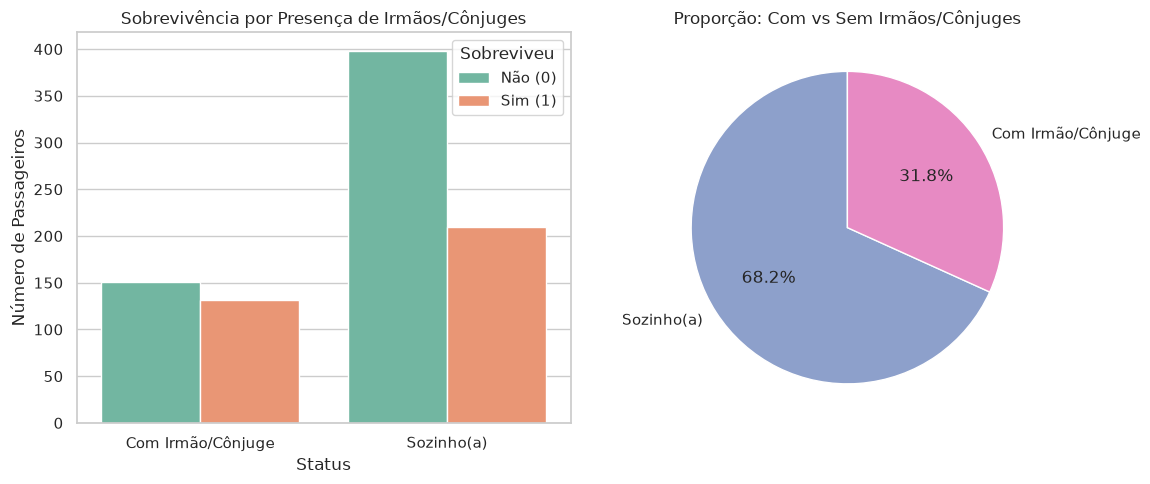

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Cria a categoria para quem tinha ou não irmãos/cônjuges
df['Has_SibSp'] = df['SibSp'].apply(lambda x: 'Com Irmão/Cônjuge' if x > 0 else 'Sozinho(a)')

plt.figure(figsize=(12, 5))

# Gráfico de Barras
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Has_SibSp', hue='Survived', palette='Set2')
plt.title('Sobrevivência por Presença de Irmãos/Cônjuges')
plt.xlabel('Status')
plt.ylabel('Número de Passageiros')
plt.legend(title='Sobreviveu', labels=['Não (0)', 'Sim (1)'])

# Gráfico de Pizza
plt.subplot(1, 2, 2)
sib_counts = df['Has_SibSp'].value_counts()
plt.pie(sib_counts, labels=sib_counts.index, autopct='%1.1f%%', colors=['#8da0cb', '#e78ac3'], startangle=90)
plt.title('Proporção: Com vs Sem Irmãos/Cônjuges')

plt.tight_layout()
plt.show()

In [18]:
# Tabela cruzada com as contagens exatas de sobreviventes por categoria de Irmãos/Cônjuges
print("--- Contagens (Barras) ---")
print(pd.crosstab(df['Has_SibSp'], df['Survived'], margins=True))

print("\n--- Percentagens (Pizza) ---")
print(df['Has_SibSp'].value_counts(normalize=True) * 100)

--- Contagens (Barras) ---
Survived             0    1  All
Has_SibSp                       
Com Irmão/Cônjuge  151  132  283
Sozinho(a)         398  210  608
All                549  342  891

--- Percentagens (Pizza) ---
Has_SibSp
Sozinho(a)           68.237935
Com Irmão/Cônjuge    31.762065
Name: proportion, dtype: float64


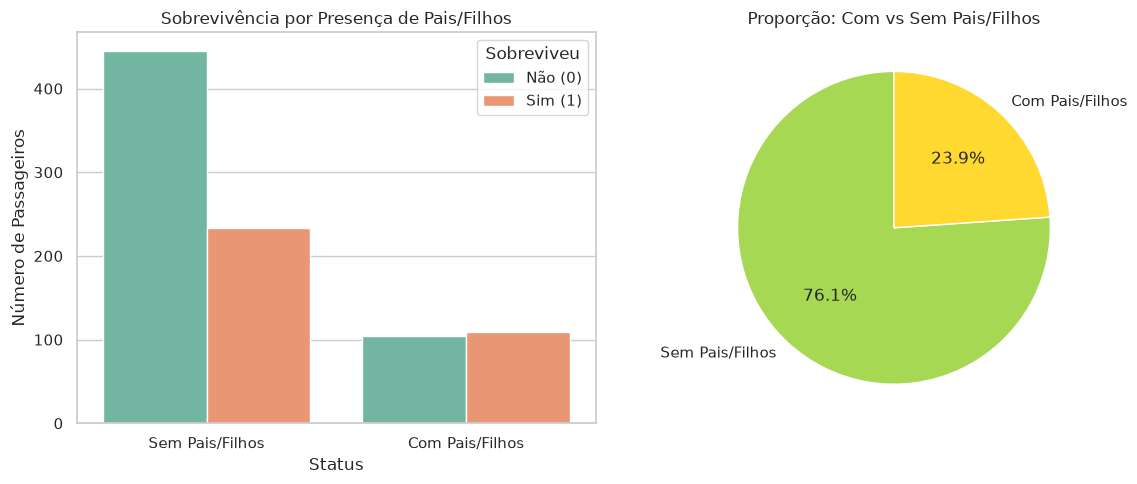

In [17]:
# Cria a categoria para quem tinha ou não pais/filhos
df['Has_Parch'] = df['Parch'].apply(lambda x: 'Com Pais/Filhos' if x > 0 else 'Sem Pais/Filhos')

plt.figure(figsize=(12, 5))

# Gráfico de Barras
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Has_Parch', hue='Survived', palette='Set2')
plt.title('Sobrevivência por Presença de Pais/Filhos')
plt.xlabel('Status')
plt.ylabel('Número de Passageiros')
plt.legend(title='Sobreviveu', labels=['Não (0)', 'Sim (1)'])

# Gráfico de Pizza
plt.subplot(1, 2, 2)
parch_counts = df['Has_Parch'].value_counts()
plt.pie(parch_counts, labels=parch_counts.index, autopct='%1.1f%%', colors=['#a6d854', '#ffd92f'], startangle=90)
plt.title('Proporção: Com vs Sem Pais/Filhos')

plt.tight_layout()
plt.show()

In [19]:
# Tabela cruzada com as contagens exatas de sobreviventes por categoria de Pais/Filhos
print("--- Contagens (Barras) ---")
print(pd.crosstab(df['Has_Parch'], df['Survived'], margins=True))

print("\n--- Percentagens (Pizza) ---")
print(df['Has_Parch'].value_counts(normalize=True) * 100)

--- Contagens (Barras) ---
Survived           0    1  All
Has_Parch                     
Com Pais/Filhos  104  109  213
Sem Pais/Filhos  445  233  678
All              549  342  891

--- Percentagens (Pizza) ---
Has_Parch
Sem Pais/Filhos    76.094276
Com Pais/Filhos    23.905724
Name: proportion, dtype: float64


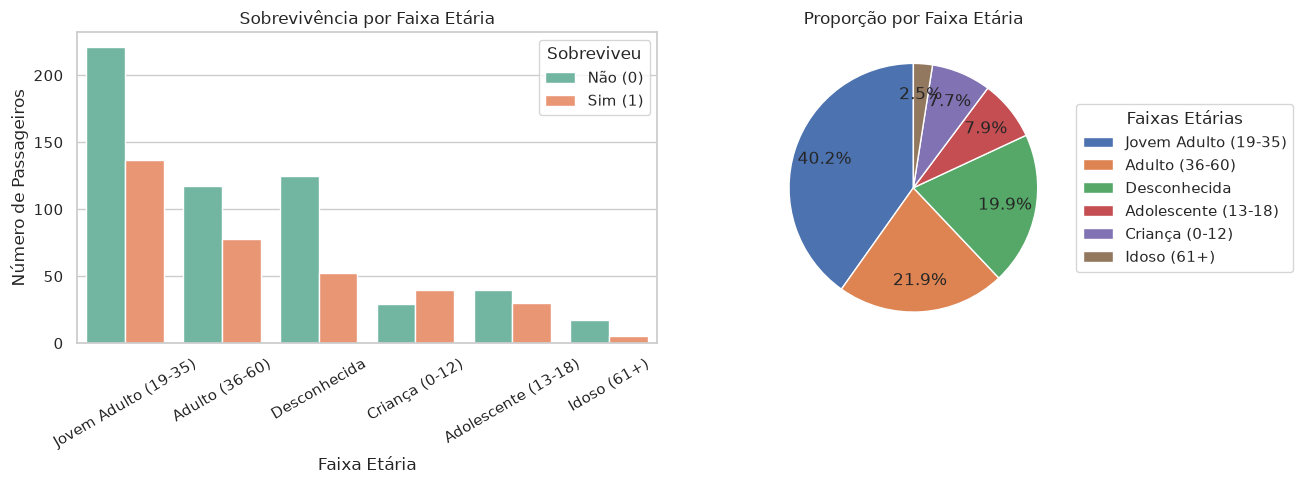

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cria bins (intervalos) para as idades e trata os valores nulos
bins = [0, 12, 18, 35, 60, 100]
labels = ['Criança (0-12)', 'Adolescente (13-18)', 'Jovem Adulto (19-35)', 'Adulto (36-60)', 'Idoso (61+)']
df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=True)
df['Age_Group'] = df['Age_Group'].astype(object).fillna('Desconhecida')

plt.figure(figsize=(14, 5))

# Gráfico de Barras
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Age_Group', hue='Survived', palette='Set2')
plt.title('Sobrevivência por Faixa Etária')
plt.xlabel('Faixa Etária')
plt.ylabel('Número de Passageiros')
plt.xticks(rotation=30)
plt.legend(title='Sobreviveu', labels=['Não (0)', 'Sim (1)'])

# Gráfico de Pizza com Legenda Lateral
plt.subplot(1, 2, 2)
age_group_counts = df['Age_Group'].value_counts()
wedges, texts, autotexts = plt.pie(age_group_counts, autopct='%1.1f%%', startangle=90, pctdistance=0.75)
plt.legend(wedges, age_group_counts.index, title="Faixas Etárias", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))
plt.title('Proporção por Faixa Etária')

plt.tight_layout()
plt.show()

In [23]:
print("--- Contagens por Faixa Etária e Sobrevivência (Barras) ---")
print(pd.crosstab(df['Age_Group'], df['Survived'], margins=True))

print("\n--- Percentagens da Proporção Total (Pizza) ---")
print(df['Age_Group'].value_counts(normalize=True) * 100)

--- Contagens por Faixa Etária e Sobrevivência (Barras) ---
Survived                0    1  All
Age_Group                          
Adolescente (13-18)    40   30   70
Adulto (36-60)        117   78  195
Criança (0-12)         29   40   69
Desconhecida          125   52  177
Idoso (61+)            17    5   22
Jovem Adulto (19-35)  221  137  358
All                   549  342  891

--- Percentagens da Proporção Total (Pizza) ---
Age_Group
Jovem Adulto (19-35)    40.179574
Adulto (36-60)          21.885522
Desconhecida            19.865320
Adolescente (13-18)      7.856341
Criança (0-12)           7.744108
Idoso (61+)              2.469136
Name: proportion, dtype: float64


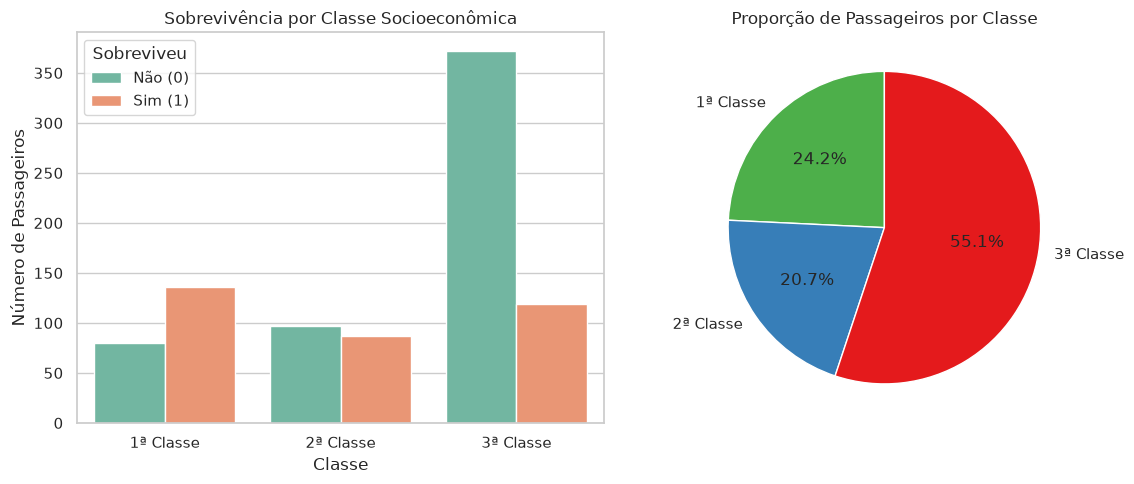

In [22]:
# Mapeia as classes para nomes mais descritivos
df['Class_Name'] = df['Pclass'].map({1: '1ª Classe', 2: '2ª Classe', 3: '3ª Classe'})

plt.figure(figsize=(12, 5))

# Gráfico de Barras
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Class_Name', hue='Survived', palette='Set2', order=['1ª Classe', '2ª Classe', '3ª Classe'])
plt.title('Sobrevivência por Classe Socioeconômica')
plt.xlabel('Classe')
plt.ylabel('Número de Passageiros')
plt.legend(title='Sobreviveu', labels=['Não (0)', 'Sim (1)'])

# Gráfico de Pizza
plt.subplot(1, 2, 2)
class_counts = df['Class_Name'].value_counts()[['1ª Classe', '2ª Classe', '3ª Classe']]
plt.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', colors=['#4daf4a', '#377eb8', '#e41a1c'], startangle=90)
plt.title('Proporção de Passageiros por Classe')

plt.tight_layout()
plt.show()

In [24]:
print("--- Contagens por Classe e Sobrevivência (Barras) ---")
print(pd.crosstab(df['Class_Name'], df['Survived'], margins=True))

print("\n--- Percentagens da Proporção Total (Pizza) ---")
print(df['Class_Name'].value_counts(normalize=True) * 100)

--- Contagens por Classe e Sobrevivência (Barras) ---
Survived      0    1  All
Class_Name               
1ª Classe    80  136  216
2ª Classe    97   87  184
3ª Classe   372  119  491
All         549  342  891

--- Percentagens da Proporção Total (Pizza) ---
Class_Name
3ª Classe    55.106622
1ª Classe    24.242424
2ª Classe    20.650954
Name: proportion, dtype: float64


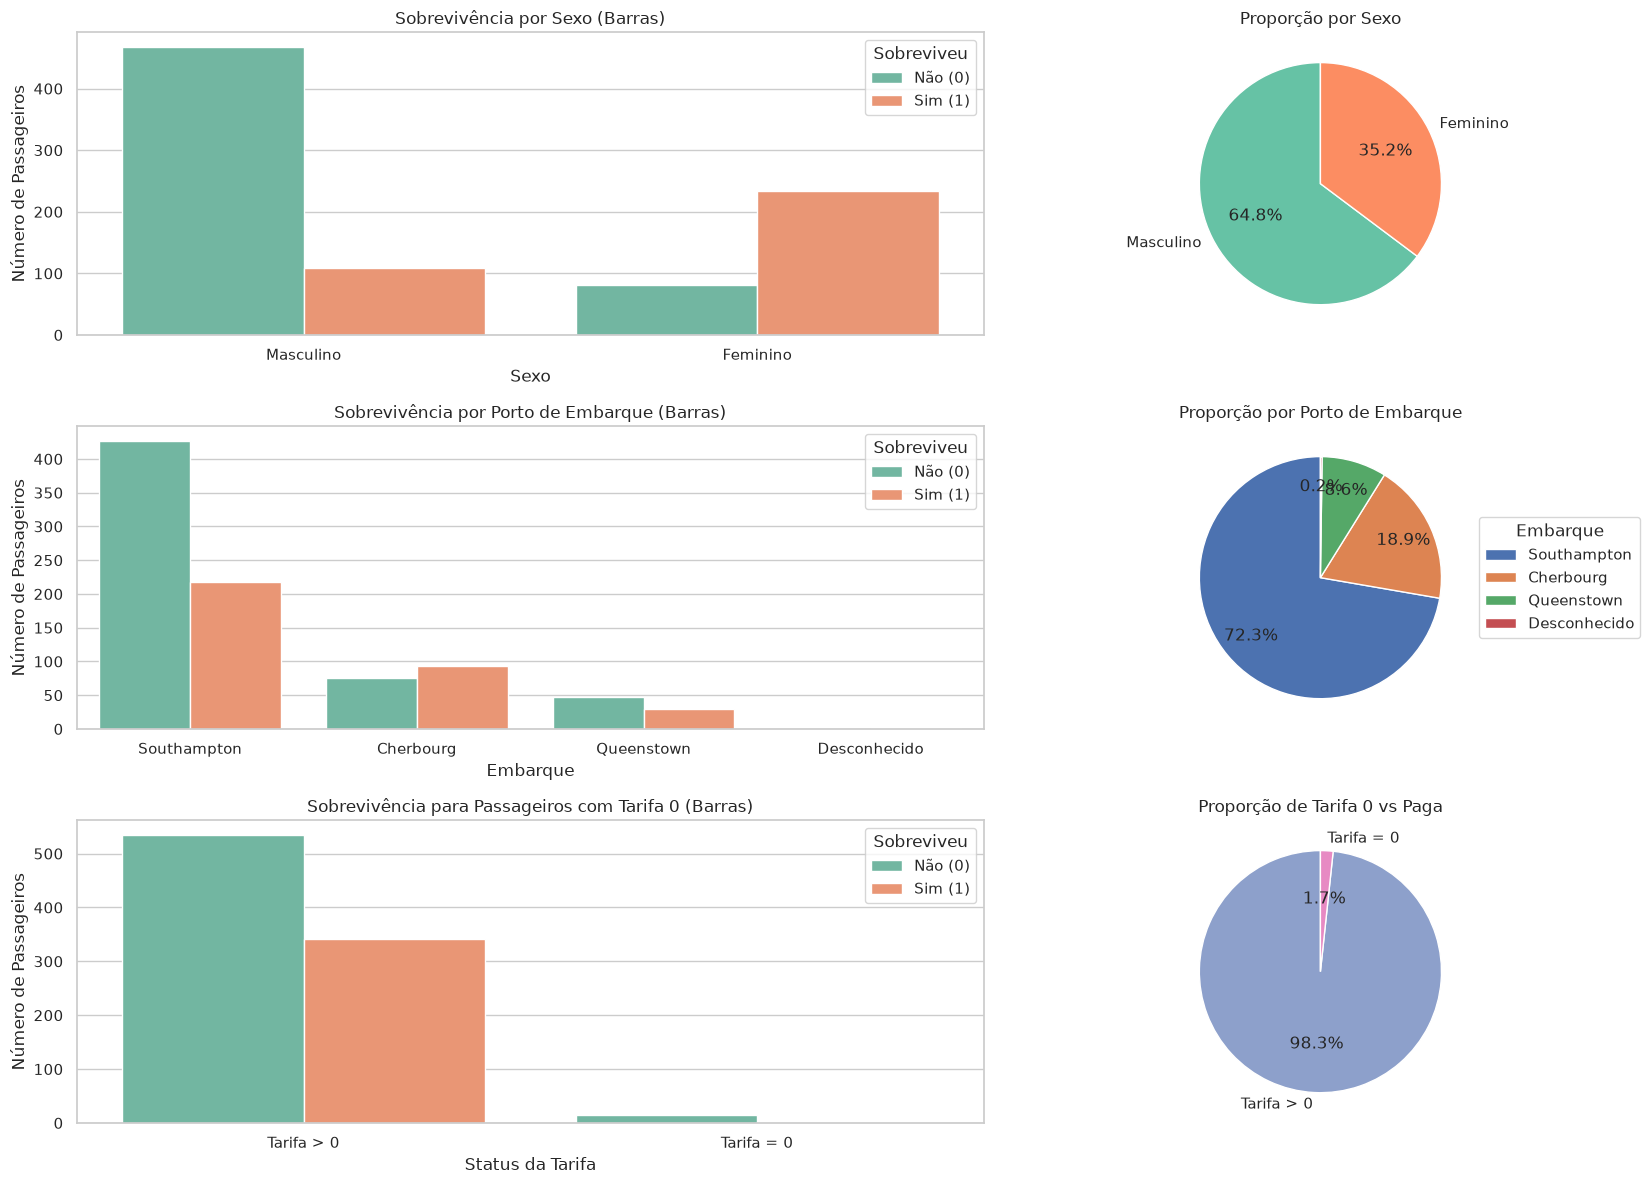

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 12))

# --- 6. Sobrevivência por Sexo ---
df['Sex_Name'] = df['Sex'].map({'male': 'Masculino', 'female': 'Feminino'})

plt.subplot(3, 2, 1)
sns.countplot(data=df, x='Sex_Name', hue='Survived', palette='Set2')
plt.title('Sobrevivência por Sexo (Barras)')
plt.xlabel('Sexo')
plt.ylabel('Número de Passageiros')
plt.legend(title='Sobreviveu', labels=['Não (0)', 'Sim (1)'])

plt.subplot(3, 2, 2)
sex_counts = df['Sex_Name'].value_counts()
plt.pie(sex_counts, labels=sex_counts.index, autopct='%1.1f%%', startangle=90, colors=['#66c2a5', '#fc8d62'])
plt.title('Proporção por Sexo')

# --- 7. Sobrevivência por Porto de Embarque ---
# C (Cherbourg), Q (Queenstown), S (Southampton), preenchendo vazios se houver
df['Embarked_Name'] = df['Embarked'].map({'C': 'Cherbourg', 'Q': 'Queenstown', 'S': 'Southampton'}).fillna('Desconhecido')

plt.subplot(3, 2, 3)
sns.countplot(data=df, x='Embarked_Name', hue='Survived', palette='Set2', order=['Southampton', 'Cherbourg', 'Queenstown', 'Desconhecido'])
plt.title('Sobrevivência por Porto de Embarque (Barras)')
plt.xlabel('Embarque')
plt.ylabel('Número de Passageiros')
plt.legend(title='Sobreviveu', labels=['Não (0)', 'Sim (1)'])

plt.subplot(3, 2, 4)
emb_counts = df['Embarked_Name'].value_counts()
wedges, texts, autotexts = plt.pie(emb_counts, autopct='%1.1f%%', startangle=90, pctdistance=0.75)
plt.legend(wedges, emb_counts.index, title="Embarque", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))
plt.title('Proporção por Porto de Embarque')

# --- 8. Sobrevivência com Tarifa Igual a 0 ---
df['Fare_Status'] = df['Fare'].apply(lambda x: 'Tarifa = 0' if x == 0 else 'Tarifa > 0')

plt.subplot(3, 2, 5)
sns.countplot(data=df, x='Fare_Status', hue='Survived', palette='Set2')
plt.title('Sobrevivência para Passageiros com Tarifa 0 (Barras)')
plt.xlabel('Status da Tarifa')
plt.ylabel('Número de Passageiros')
plt.legend(title='Sobreviveu', labels=['Não (0)', 'Sim (1)'])

plt.subplot(3, 2, 6)
fare_counts = df['Fare_Status'].value_counts()
plt.pie(fare_counts, labels=fare_counts.index, autopct='%1.1f%%', startangle=90, colors=['#8da0cb', '#e78ac3'])
plt.title('Proporção de Tarifa 0 vs Paga')

plt.tight_layout()
plt.show()

In [26]:
print("--- 1. Sexo ---")
print(pd.crosstab(df['Sex_Name'], df['Survived'], margins=True))
print(df['Sex_Name'].value_counts(normalize=True) * 100)

print("\n--- 2. Porto de Embarque ---")
print(pd.crosstab(df['Embarked_Name'], df['Survived'], margins=True))
print(df['Embarked_Name'].value_counts(normalize=True) * 100)

print("\n--- 3. Tarifa Zero ---")
print(pd.crosstab(df['Fare_Status'], df['Survived'], margins=True))
print(df['Fare_Status'].value_counts(normalize=True) * 100)

--- 1. Sexo ---
Survived     0    1  All
Sex_Name                
Feminino    81  233  314
Masculino  468  109  577
All        549  342  891
Sex_Name
Masculino    64.758698
Feminino     35.241302
Name: proportion, dtype: float64

--- 2. Porto de Embarque ---
Survived         0    1  All
Embarked_Name               
Cherbourg       75   93  168
Desconhecido     0    2    2
Queenstown      47   30   77
Southampton    427  217  644
All            549  342  891
Embarked_Name
Southampton     72.278339
Cherbourg       18.855219
Queenstown       8.641975
Desconhecido     0.224467
Name: proportion, dtype: float64

--- 3. Tarifa Zero ---
Survived       0    1  All
Fare_Status               
Tarifa = 0    14    1   15
Tarifa > 0   535  341  876
All          549  342  891
Fare_Status
Tarifa > 0    98.316498
Tarifa = 0     1.683502
Name: proportion, dtype: float64


/tmp/xpython_42/878338786.py:24: SyntaxWarning: invalid escape sequence '\.'
  df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)


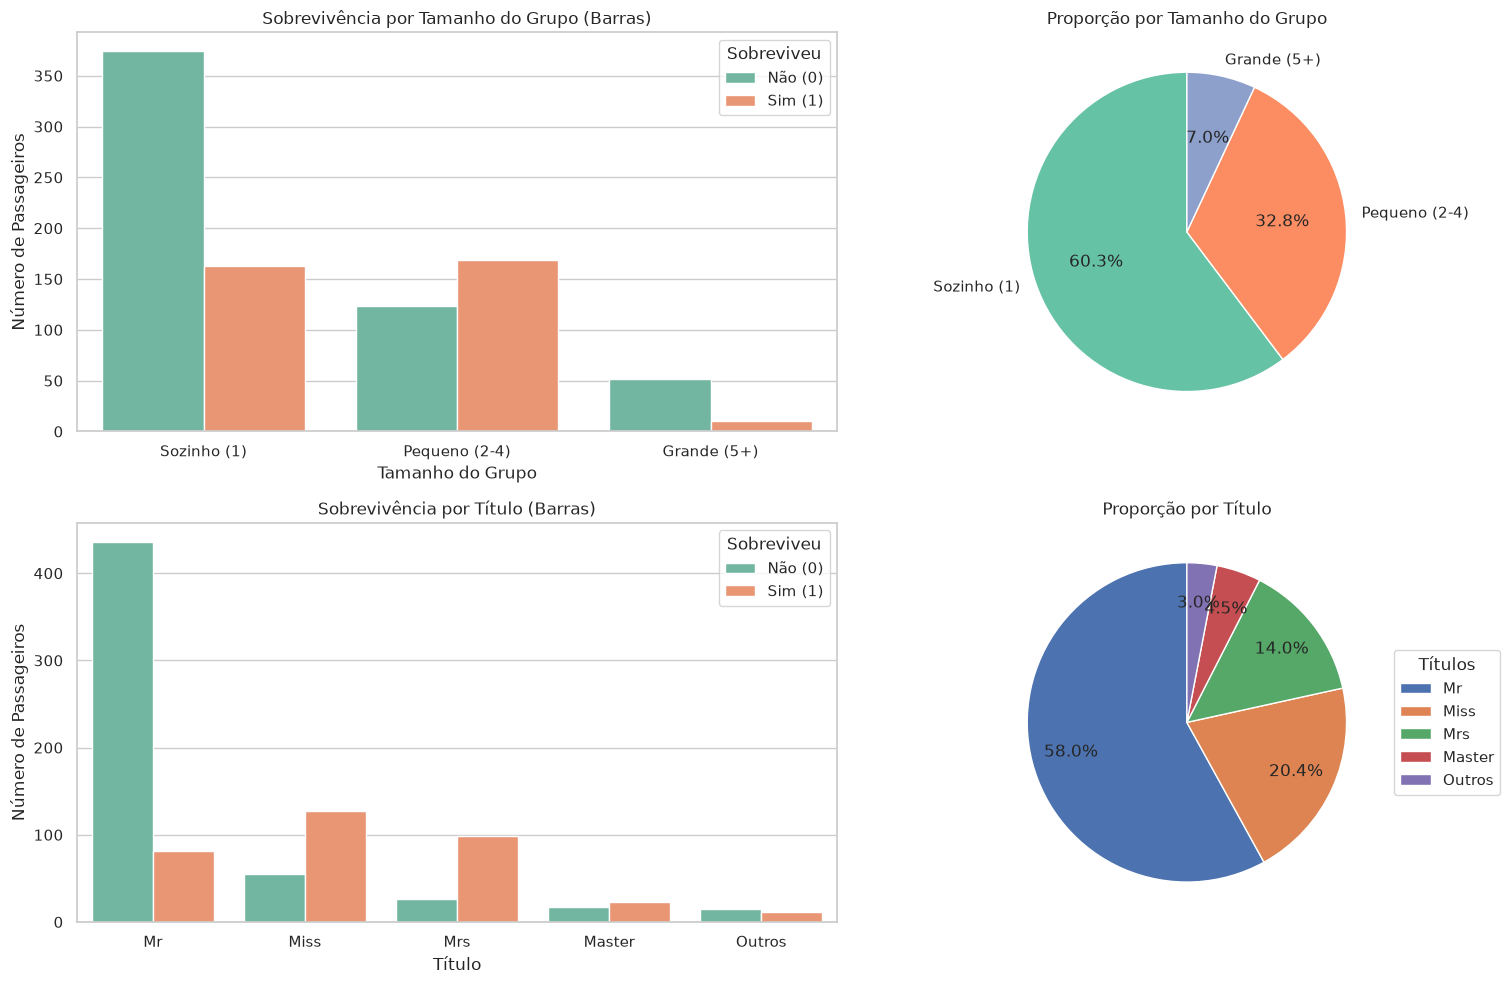

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 10))

# --- 9. Tamanho do Grupo de Viagem ---
df['Family_Size'] = df['SibSp'] + df['Parch'] + 1
df['Group_Category'] = df['Family_Size'].apply(lambda x: 'Sozinho (1)' if x == 1 else ('Pequeno (2-4)' if 2 <= x <= 4 else 'Grande (5+)'))

plt.subplot(2, 2, 1)
sns.countplot(data=df, x='Group_Category', hue='Survived', palette='Set2', order=['Sozinho (1)', 'Pequeno (2-4)', 'Grande (5+)'])
plt.title('Sobrevivência por Tamanho do Grupo (Barras)')
plt.xlabel('Tamanho do Grupo')
plt.ylabel('Número de Passageiros')
plt.legend(title='Sobreviveu', labels=['Não (0)', 'Sim (1)'])

plt.subplot(2, 2, 2)
group_counts = df['Group_Category'].value_counts()[['Sozinho (1)', 'Pequeno (2-4)', 'Grande (5+)']]
plt.pie(group_counts, labels=group_counts.index, autopct='%1.1f%%', startangle=90, colors=['#66c2a5', '#fc8d62', '#8da0cb'])
plt.title('Proporção por Tamanho do Grupo')

# --- 10. Títulos dos Passageiros ---
df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)
title_mapping = {'Mr': 'Mr', 'Miss': 'Miss', 'Mrs': 'Mrs', 'Master': 'Master'}
df['Title_Group'] = df['Title'].map(title_mapping).fillna('Outros')

plt.subplot(2, 2, 3)
sns.countplot(data=df, x='Title_Group', hue='Survived', palette='Set2', order=['Mr', 'Miss', 'Mrs', 'Master', 'Outros'])
plt.title('Sobrevivência por Título (Barras)')
plt.xlabel('Título')
plt.ylabel('Número de Passageiros')
plt.legend(title='Sobreviveu', labels=['Não (0)', 'Sim (1)'])

plt.subplot(2, 2, 4)
title_counts = df['Title_Group'].value_counts()
wedges, texts, autotexts = plt.pie(title_counts, autopct='%1.1f%%', startangle=90, pctdistance=0.75)
plt.legend(wedges, title_counts.index, title="Títulos", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))
plt.title('Proporção por Título')

plt.tight_layout()
plt.show()

In [28]:
print("--- Tamanho do Grupo ---")
print(pd.crosstab(df['Group_Category'], df['Survived'], margins=True))

print("\n--- Títulos ---")
print(pd.crosstab(df['Title_Group'], df['Survived'], margins=True))

--- Tamanho do Grupo ---
Survived          0    1  All
Group_Category               
Grande (5+)      52   10   62
Pequeno (2-4)   123  169  292
Sozinho (1)     374  163  537
All             549  342  891

--- Títulos ---
Survived       0    1  All
Title_Group               
Master        17   23   40
Miss          55  127  182
Mr           436   81  517
Mrs           26   99  125
Outros        15   12   27
All          549  342  891
